# 05 · Backtest: Would the radar have worked in the past? And which method is better?

This is the notebook to show a sceptical investor. The question is:

> *Standing in year t, with only the data available then, would each method have
> told the future SEA booms apart from the hype that fizzled?*

**Evaluation design:**
* **Universe:** the labelled sectors (7 booms, 12 noise) with search data back to their decision window.
  The 6 ambiguous ones are excluded.
* **When:** only the years in which a VC actually had to decide:
  * booms: the **4 years before the SEA breakout year** (t = breakout−4 … breakout−1), i.e. pure prediction
  * noise: the **hype window**, from 2 years before the historically dated hype peak up to the peak

> **Revision note.** A first run defined the windows from the search data itself ("active" = ≥30% of
> running peak). That was a bug: near-zero noise early in a series counted as "active", so booms were
> scored from 2009, and an artifact jump in 2026 search data moved several hype peaks to 2026. The
> windows were replaced with the fixed, historically dated windows above. The preliminary results
> are kept in this note for transparency: A = 0.73, B = 0.58, buzz baseline = 0.63.
* **Metric:** ROC-AUC (the probability that a random boom-year scores above a random noise-year).
  95% CIs come from a **sector-level bootstrap**: whole sectors are resampled, because years
  within a sector are not independent.
* **Benchmarks:** (i) a coin flip = 0.50; (ii) **"follow the buzz"**, which ranks by 2-year growth in
  SF attention, i.e. what a hype-driven investor does.
* **Significance:** a label permutation test that shuffles boom/noise labels across sectors.

**Honest caveat on sample size:** 19 sectors is small. Treat the numbers as evidence that
the method is directionally right, not as a precise accuracy figure.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

sys.path.insert(0, str(Path.cwd().parent))
from radar.config import PROC, FIG, SECTORS, LABELLED
warnings.filterwarnings("ignore")
rng = np.random.default_rng(42)

A = pd.read_parquet(PROC / "method_A_scores.parquet")
B = pd.read_parquet(PROC / "method_B_scores.parquet")
sectors = pd.read_parquet(PROC / "sectors.parquet")
df = A.merge(B[["sector", "year", "score_B", "score_B1", "score_B2"]], on=["sector", "year"])
df["ensemble"] = df[["score_A", "score_B"]].mean(axis=1)
df["y"] = (df.label == "boom").astype(int)

## 1 · Build the evaluation set (decision windows)

In [2]:
def in_window(r):
    if r.label == "boom":
        yb = sectors.sea_boom_year[r.sector]
        return yb - 4 <= r.year <= yb - 1
    if r.label == "noise":
        yp = sectors.hype_peak[r.sector]
        return yp - 2 <= r.year <= yp
    return False

ev = df[df.sector.isin(LABELLED)].copy()
ev = ev[ev.apply(in_window, axis=1)]
ev = ev.dropna(subset=["score_A", "score_B", "baseline_momentum"])
print(f"{len(ev)} sector-years | {ev.sector.nunique()} sectors | booms={ev[ev.y==1].sector.nunique()} noise={ev[ev.y==0].sector.nunique()}")
ev.groupby(["label", "sector"]).year.agg(["min", "max", "count"])

56 sector-years | 17 sectors | booms=7 noise=10


min   max  count
label sector                                 
boom  bnpl                  2016  2019      4
      digital_banks         2017  2020      4
      digital_payments      2013  2016      4
      food_delivery         2014  2017      4
      retail_investing      2017  2020      4
      ride_hailing          2011  2014      4
      video_streaming       2012  2015      4
noise cloud_kitchens        2018  2020      3
      consumer_3d_printing  2011  2013      3
      coworking             2017  2019      3
      drone_delivery        2015  2016      2
      ibuying               2019  2021      3
      metaverse             2020  2022      3
      nft                   2019  2021      3
      play_to_earn          2020  2021      2
      quick_commerce        2019  2021      3
      social_audio          2019  2021      3

## 2 · Headline: AUC with sector-bootstrap CIs and permutation p-values

In [3]:
METHODS = {"Method A (convergence)": "score_A", "Method B (time-series + ML)": "score_B",
           "  B1 statistics only": "score_B1", "  B2 ML only": "score_B2",
           "Ensemble (A+B)/2": "ensemble", "Baseline: follow the buzz": "baseline_momentum"}

def auc(d, col):
    d = d.dropna(subset=[col])
    return roc_auc_score(d.y, d[col]) if d.y.nunique() == 2 else np.nan

def boot_ci(d, col, n=2000):
    d = d.dropna(subset=[col])
    if d.y.nunique() < 2: return [np.nan, np.nan]
    secs = d.sector.unique(); out = []
    groups = {s: g for s, g in d.groupby("sector")}
    for _ in range(n):
        smp = pd.concat([groups[s] for s in rng.choice(secs, len(secs), replace=True)])
        a = auc(smp, col)
        if not np.isnan(a): out.append(a)
    return np.percentile(out, [2.5, 97.5])

def perm_p(d, col, n=2000):
    d = d.dropna(subset=[col])
    obs = auc(d, col)
    if np.isnan(obs): return np.nan
    lab = d.groupby("sector").y.first()
    null = []
    for _ in range(n):
        perm = pd.Series(rng.permutation(lab.values), index=lab.index)
        null.append(auc(d.assign(y=d.sector.map(perm)), col))
    return np.mean(np.array(null) >= obs)

rows = []
for name, col in METHODS.items():
    lo, hi = boot_ci(ev, col)
    rows.append(dict(method=name, AUC=auc(ev, col), CI_low=lo, CI_high=hi, perm_p=perm_p(ev, col)))
headline = pd.DataFrame(rows).set_index("method").round(3)
headline.to_csv(PROC / "backtest_headline.csv")
headline

,AUC,CI_low,CI_high,perm_p
method,,,,
Method A (convergence),0.617,0.448,0.767,0.095
Method B (time-series + ML),0.524,0.311,0.750,0.428
B1 statistics only,0.561,0.330,0.804,0.304
B2 ML only,0.269,0.118,0.435,0.990
Ensemble (A+B)/2,0.602,0.392,0.810,0.208
Baseline: follow the buzz,0.372,0.177,0.576,0.864


## 3 · The "peak hype" stress test
The most dangerous moment for an investor is **peak hype**. For each fad we take its historical
hype-peak year. For each boom we take the year **two years before** its SEA breakout. Then we read off
the scores computed *at that time*, using only data available then.

In [4]:
def decision_year(s):
    if sectors.label[s] == "noise":
        return int(sectors.hype_peak[s])            # peak hype, dated historically
    return int(sectors.sea_boom_year[s]) - 2       # two years before the SEA breakout

stress = []
for s in LABELLED:
    t = decision_year(s)
    r = df[(df.sector == s) & (df.year == t)]
    if len(r):
        r = r.iloc[0]
        stress.append(dict(sector=s, label=r.label, decision_year=t, A=r.score_A, B=r.score_B,
                           ensemble=r.ensemble, buzz=r.baseline_momentum))
stress = pd.DataFrame(stress).set_index("sector").sort_values(["label", "ensemble"])
stress["buzz_rank"] = stress.buzz.rank(pct=True)
stress.round(2)

,label,decision_year,A,B,ensemble,buzz,buzz_rank
sector,,,,,,,
video_streaming,boom,2014,0.49,0.74,0.61,-0.15,0.05
digital_payments,boom,2015,0.72,0.63,0.67,0.65,0.32
retail_investing,boom,2019,0.89,0.46,0.68,0.13,0.11
digital_banks,boom,2019,0.84,0.69,0.76,1.24,0.53
food_delivery,boom,2016,0.68,0.89,0.79,0.75,0.37
ride_hailing,boom,2013,0.64,0.95,0.80,1.54,0.68
bnpl,boom,2018,0.94,0.91,0.92,0.54,0.26
play_to_earn,noise,2021,0.59,0.51,0.55,2.32,0.84
social_audio,noise,2021,0.58,0.62,0.60,2.05,0.74


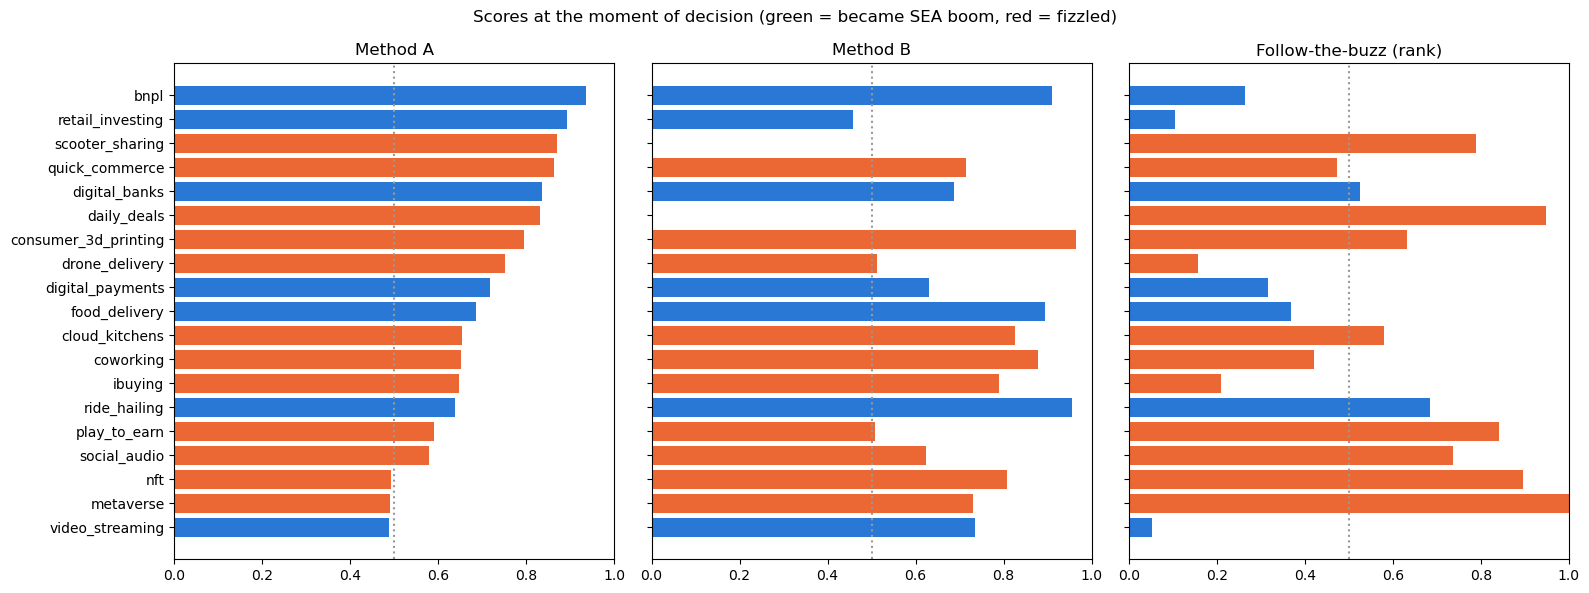

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
COL = {"boom": "#2a78d6", "noise": "#eb6834"}
for ax, col, title in zip(axes, ["A", "B", "buzz_rank"], ["Method A", "Method B", "Follow-the-buzz (rank)"]):
    d = stress.sort_values(col)
    ax.barh(d.index, d[col], color=[COL[l] for l in d.label])
    ax.axvline(0.5, color="#999", ls=":"); ax.set_title(title); ax.set_xlim(0, 1)
plt.suptitle("Scores at the moment of decision (green = became SEA boom, red = fizzled)")
plt.tight_layout(); plt.savefig(FIG / "05_peak_hype_stress_test.png", dpi=150); plt.show()

## 4 · Lead time: how early would each method have flagged the SEA booms?
A boom counts as **flagged** in the first year (within the 6 years before breakout) its score crosses
0.55 (a threshold fixed in advance). Lead time = SEA breakout year − flag year, so the maximum is 6.

In [6]:
THR = 0.55
lead = []
for s in [x for x in LABELLED if sectors.label[x] == "boom"]:
    yb = int(sectors.sea_boom_year[s]); d = df[df.sector == s].set_index("year")
    row = dict(sector=s, sea_boom_year=yb)
    for name, col in [("A", "score_A"), ("B", "score_B"), ("ensemble", "ensemble")]:
        hit = d[(d[col] >= THR) & (d.index <= yb) & (d.index >= yb - 6)]
        row[f"flag_{name}"] = int(hit.index.min()) if len(hit) else None
        row[f"lead_{name}"] = yb - hit.index.min() if len(hit) else None
    lead.append(row)
lead = pd.DataFrame(lead).set_index("sector")
fa = []
for s in [x for x in LABELLED if sectors.label[x] == "noise"]:
    d = ev[ev.sector == s]
    fa.append(dict(sector=s, **{f"false_alarm_{k}": bool((d[c] >= THR).any()) for k, c in
                               [("A", "score_A"), ("B", "score_B"), ("ensemble", "ensemble")]}))
fa = pd.DataFrame(fa).set_index("sector")
print("Booms flagged before SEA breakout:", lead[["flag_A", "flag_B", "flag_ensemble"]].notna().sum().to_dict())
print("Median lead (years):", lead[["lead_A", "lead_B", "lead_ensemble"]].median().to_dict())
print("Noise sectors that triggered a false alarm during hype window:", fa.sum().to_dict(), "of", len(fa))
lead

Booms flagged before SEA breakout: {'flag_A': 7, 'flag_B': 7, 'flag_ensemble': 7}
Median lead (years): {'lead_A': 6.0, 'lead_B': 6.0, 'lead_ensemble': 6.0}
Noise sectors that triggered a false alarm during hype window: {'false_alarm_A': 10, 'false_alarm_B': 10, 'false_alarm_ensemble': 10} of 12


,sea_boom_year,flag_A,lead_A,flag_B,lead_B,flag_ensemble,lead_ensemble
sector,,,,,,,
ride_hailing,2015,2009,6,2009,6,2009,6
food_delivery,2018,2012,6,2012,6,2012,6
digital_payments,2017,2011,6,2011,6,2011,6
bnpl,2020,2014,6,2014,6,2014,6
digital_banks,2021,2015,6,2015,6,2015,6
retail_investing,2021,2015,6,2015,6,2015,6
video_streaming,2016,2010,6,2010,6,2010,6


## 5 · Robustness: does Method A depend on the exact weights?
Draw 2,000 random weight vectors from a flat Dirichlet distribution, so any weighting is
equally likely, and recompute the AUC. If the method only worked with our hand-picked weights,
this distribution would be centred near 0.5.

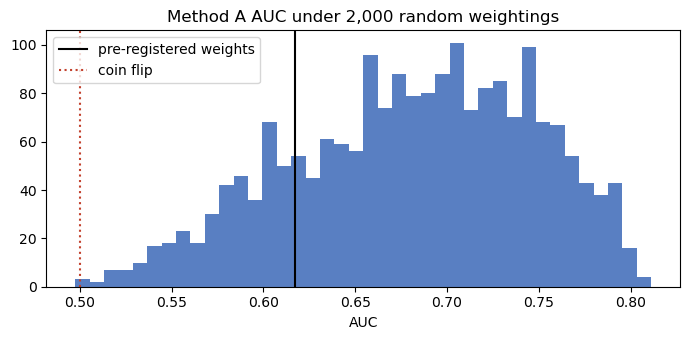

random-weight AUC: median=0.688, 5th pct=0.566, share>0.5 = 99.90%


diffusion      0.755
low_spike      0.636
holding        0.545
persistence    0.498
substance      0.476
breadth        0.464
dtype: float64

In [7]:
COMP = ["breadth", "substance", "persistence", "low_spike", "holding", "diffusion"]
X = ev[COMP].values
def score_w(w):
    W = np.where(np.isnan(X), 0, w); V = np.nan_to_num(X)
    return (V * W).sum(1) / np.maximum(W.sum(1), 1e-9)
aucs = np.array([roc_auc_score(ev.y, score_w(rng.dirichlet(np.ones(len(COMP))))) for _ in range(2000)])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(aucs, bins=40, color="#2f5fb3", alpha=.8)
ax.axvline(headline.loc["Method A (convergence)", "AUC"], color="k", label="pre-registered weights")
ax.axvline(0.5, color="#c2412d", ls=":", label="coin flip")
ax.set_xlabel("AUC"); ax.legend(); ax.set_title("Method A AUC under 2,000 random weightings")
plt.tight_layout(); plt.savefig(FIG / "05_weight_robustness.png", dpi=150); plt.show()
print(f"random-weight AUC: median={np.median(aucs):.3f}, 5th pct={np.percentile(aucs,5):.3f}, share>0.5 = {(aucs>0.5).mean():.2%}")

# single-component AUCs (which ingredients carry the signal?)
comp_auc = pd.Series({c: auc(ev, c) for c in COMP}).sort_values(ascending=False).round(3)
comp_auc

## 6 · Leave-one-sector-out: could a *learned* combination beat fixed weights?
A logistic regression on A's components plus B1/B2, trained with each sector held out in turn.
With this little data, matching the fixed weights is already a good result. Beating them by a lot would point to overfitting.

In [8]:
feat = COMP + ["score_B1", "score_B2"]
loso = []
for s in ev.sector.unique():
    tr, te = ev[ev.sector != s], ev[ev.sector == s]
    Xtr, Xte = tr[feat].fillna(tr[feat].median()), te[feat].fillna(tr[feat].median())
    m = LogisticRegression(C=0.5, max_iter=1000).fit(Xtr, tr.y)
    loso.append(te.assign(p_loso=m.predict_proba(Xte)[:, 1]))
loso = pd.concat(loso)
print(f"LOSO learned-combination AUC: {auc(loso, 'p_loso'):.3f}  vs  fixed ensemble {auc(ev, 'ensemble'):.3f}")

LOSO learned-combination AUC: 0.241  vs  fixed ensemble 0.602


## 7 · Method A vs Method B: do they agree?

Spearman rho(A, B) over all sector-years: 0.05
B says trend  False  True 
A says trend              
False             0      5
True              2     49
A=False B=True : n=  5  share that were real booms = 0.40
A=True  B=False: n=  2  share that were real booms = 0.50
A=True  B=True : n= 49  share that were real booms = 0.51


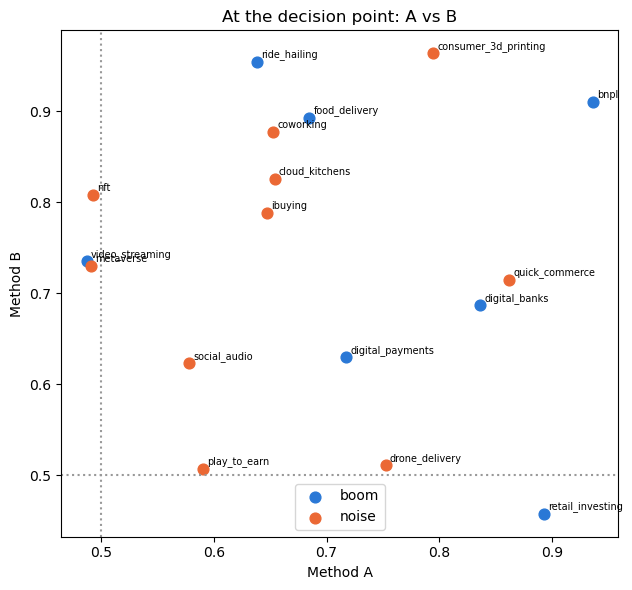

In [9]:
rho = stats.spearmanr(df.score_A, df.score_B, nan_policy="omit")
print(f"Spearman rho(A, B) over all sector-years: {rho.correlation:.2f}")
agree = ev.assign(A_call=ev.score_A >= 0.5, B_call=ev.score_B >= 0.5)
ct = pd.crosstab(agree.A_call, agree.B_call, rownames=["A says trend"], colnames=["B says trend"])
print(ct)
for (a, b), g in agree.groupby(["A_call", "B_call"]):
    print(f"A={a!s:5} B={b!s:5}: n={len(g):3d}  share that were real booms = {g.y.mean():.2f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
for l, g in stress.groupby("label"):
    ax.scatter(g.A, g.B, color=COL[l], s=60, label=l)
    for s, r in g.iterrows(): ax.annotate(s, (r.A, r.B), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(0.5, color="#999", ls=":"); ax.axvline(0.5, color="#999", ls=":")
ax.set_xlabel("Method A"); ax.set_ylabel("Method B"); ax.legend()
ax.set_title("At the decision point: A vs B")
plt.tight_layout(); plt.savefig(FIG / "05_A_vs_B.png", dpi=150); plt.show()

In [10]:
stress.to_parquet(PROC / "backtest_stress.parquet")
ev.to_parquet(PROC / "backtest_eval_set.parquet")
lead.to_parquet(PROC / "backtest_lead.parquet")
pd.Series(aucs).to_frame("auc").to_parquet(PROC / "backtest_weight_aucs.parquet")
comp_auc.to_frame("auc").to_parquet(PROC / "backtest_component_auc.parquet")

## 8 · Exploratory (post-hoc): which individual signals carry information?
**Read this as hypothesis generation, not a validated result.** These tests were run *after* seeing that
the pre-registered composites were weak. Some signals are inverted, which was decided after seeing their
direction. With ~6 signals examined, a Bonferroni-style correction multiplies each p-value by ~6.

In [11]:
B2s = pd.read_parquet(PROC / "method_B_scores.parquet")[["sector", "year", "score_B2"]].rename(columns={"score_B2": "b2"})
evx = ev.drop(columns=["b2"], errors="ignore").merge(B2s, on=["sector", "year"], how="left")
def single(col, sign=1):
    d = evx.dropna(subset=[col]); d = d.assign(x=sign * d[col])
    lo, hi = boot_ci(d, "x"); return dict(n_sector_years=len(d), sectors=d.sector.nunique(), AUC=auc(d, "x"),
                                          CI_low=lo, CI_high=hi, perm_p=perm_p(d, "x"))
explo = pd.DataFrame({
    "SF-SEA synchronisation (low = good)": single("sync", -1),
    "Founder momentum, B2 (INVERTED)": single("b2", -1),
    "Follow the buzz (INVERTED)": single("baseline_momentum", -1),
    "Low spikiness": single("low_spike", 1),
}).T.round(3)
explo

,n_sector_years,sectors,AUC,CI_low,CI_high,perm_p
SF-SEA synchronisation (low = good),43.0,13.0,0.771,0.486,1.000,0.025
"Founder momentum, B2 (INVERTED)",38.0,14.0,0.731,0.547,0.879,0.011
Follow the buzz (INVERTED),56.0,17.0,0.628,0.416,0.808,0.112
Low spikiness,50.0,15.0,0.636,0.445,0.812,0.110


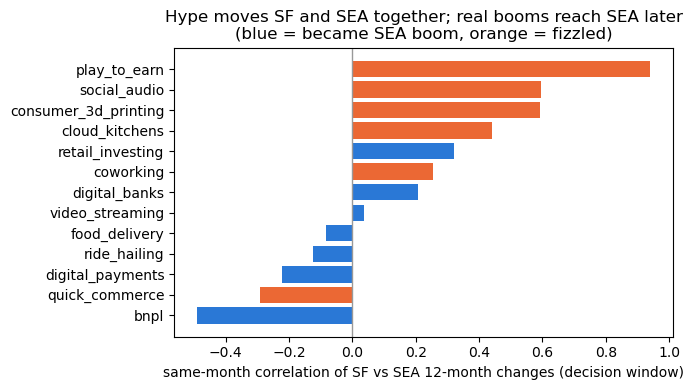

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
d = evx.dropna(subset=["sync"]).groupby(["sector", "label"]).sync.mean().reset_index().sort_values("sync")
ax.barh(d.sector, d.sync, color=[COL[l] for l in d.label])
ax.axvline(0, color="#999", lw=1)
ax.set_xlabel("same-month correlation of SF vs SEA 12-month changes (decision window)")
ax.set_title("Hype moves SF and SEA together; real booms reach SEA later\n(blue = became SEA boom, orange = fizzled)")
plt.tight_layout(); plt.savefig(FIG / "05_sync_signature.png", dpi=150); plt.show()

## 9 · Verdict
**Pre-registered result (the honest headline):** at the moment of decision, neither composite score reliably
separates future SEA booms from hype. Method A reaches AUC ≈ 0.62 (95% CI includes 0.5, permutation p ≈ 0.1).
Method B and the ensemble are close to a coin flip. Fixed thresholds flag nearly every hot sector, so
**the composites as built are not investment signals.** The earlier, flattering numbers (A = 0.73) came from
a window-definition bug and are retracted (see the revision note at the top).

**What does hold up, and is worth testing on fresh data:**
1. **Timing beats volume.** Hype waves move SF and SEA search interest *in the same month* (global media cycle).
   Real booms show up in SEA ~10–14 months later. Of all the components, synchronisation is the best
   separator (AUC ≈ 0.77, perm p ≈ 0.03 before multiple-testing correction, 13 sectors).
2. **Crowd signals are contrarian.** Both "follow the buzz" (attention momentum) and YC founder momentum score
   *higher* for hype than for booms. Founders and media chase the same waves.
3. **Weights don't rescue or sink Method A.** Across 2,000 random weightings the median AUC is ≈ 0.69. Whatever
   signal it has comes from the synchronisation and spikiness components, not from tuning.

**Method A vs Method B:** they barely agree (Spearman ≈ 0.05). A is the more useful of the two because its
parts are interpretable, and that interpretability is how the synchronisation signal was found.

**Next step to turn this into evidence:** pre-register a synchronisation-led score now, then score it on hype
waves and booms that resolve *after* today. That is the only test free of hindsight.